In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_float32_matmul_precision('high')

print(torch.__version__)      # If it has "+cpu", it's the wrong version
print(torch.version.cuda)
print(torch.cuda.is_available())
#print(torch.cuda.get_device_name(0))

print(device)

2.11.0+cpu
None
False
cpu


In [6]:
from torchvision.transforms import ToTensor

train_data = torchvision.datasets.MNIST(
    root = 'data',
    train = True,
    transform = ToTensor(),
    download = True,
)

trainloader = torch.utils.data.DataLoader(
    train_data,
    batch_size=100,
    shuffle=True,
    num_workers=1,
)

test_data = torchvision.datasets.MNIST(
    root = 'data',
    train = False,
    transform = ToTensor(),
)

testloader = torch.utils.data.DataLoader(
    test_data,
    batch_size=100,
    shuffle=False,
    num_workers=1,
    )

100%|██████████| 9.91M/9.91M [00:00<00:00, 39.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.02MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.03MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.10MB/s]


In [7]:
print(train_data)
print('Input size:', train_data.data.size())
print('Output size:', train_data.targets.size())

Dataset MNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()
Input size: torch.Size([60000, 28, 28])
Output size: torch.Size([60000])


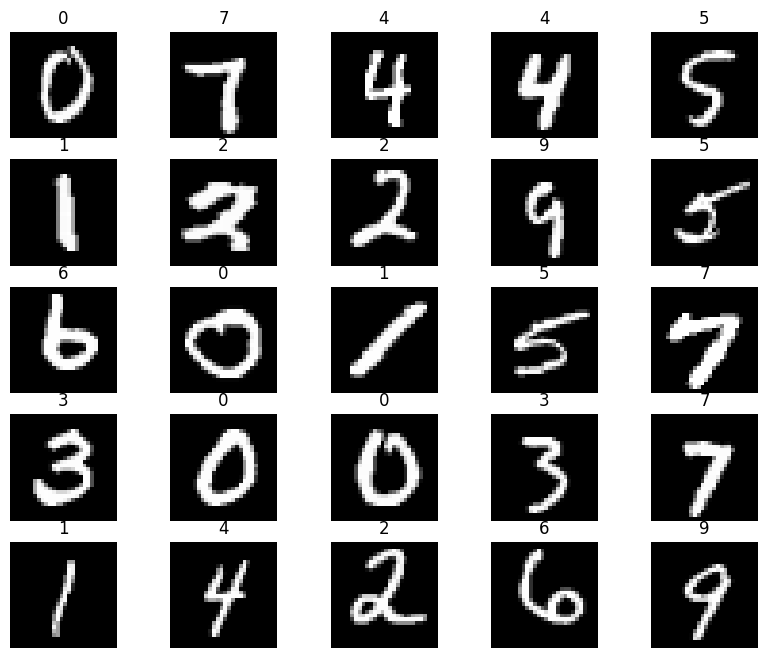

In [8]:
figure = plt.figure(figsize=(10,8))
cols, rows = 5, 5
for i in range (1, cols * rows + 1):
    sample_idx = torch.randint(len(train_data), size=(1,)).item()
    img, label = train_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(label)
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [9]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.softmax(self.fc2(x), dim=1)
        return(x)

net = Net().to(device)
print(net)

Net(
  (fc1): Linear(in_features=784, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=10, bias=True)
)


In [10]:
loss_func = nn.CrossEntropyLoss()

optimizer = optim.Adam(net.parameters(), lr = 0.001)

In [11]:
num_epochs = 20
total_step = len(trainloader)

for epoch in range(num_epochs):

        for i, data in enumerate(trainloader, 0):
            inputs, labels = data

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = net(inputs).to(device)
            loss = loss_func(outputs, labels)
            loss.backward()
            optimizer.step()

            if (i+1) % 100 == 0:
                print('Epoch[{}/{}], Step[{},{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, i + 1, total_step, loss.item()))

Epoch[1/20], Step[100,600], Loss: 1.7279
Epoch[1/20], Step[200,600], Loss: 1.5818
Epoch[1/20], Step[300,600], Loss: 1.5752
Epoch[1/20], Step[400,600], Loss: 1.5681
Epoch[1/20], Step[500,600], Loss: 1.5492
Epoch[1/20], Step[600,600], Loss: 1.5533
Epoch[2/20], Step[100,600], Loss: 1.5571
Epoch[2/20], Step[200,600], Loss: 1.5822
Epoch[2/20], Step[300,600], Loss: 1.5638
Epoch[2/20], Step[400,600], Loss: 1.5487
Epoch[2/20], Step[500,600], Loss: 1.5495
Epoch[2/20], Step[600,600], Loss: 1.5053
Epoch[3/20], Step[100,600], Loss: 1.5423
Epoch[3/20], Step[200,600], Loss: 1.5728
Epoch[3/20], Step[300,600], Loss: 1.5114
Epoch[3/20], Step[400,600], Loss: 1.5178
Epoch[3/20], Step[500,600], Loss: 1.5214
Epoch[3/20], Step[600,600], Loss: 1.5610
Epoch[4/20], Step[100,600], Loss: 1.5439
Epoch[4/20], Step[200,600], Loss: 1.5390
Epoch[4/20], Step[300,600], Loss: 1.5209
Epoch[4/20], Step[400,600], Loss: 1.5389
Epoch[4/20], Step[500,600], Loss: 1.5610
Epoch[4/20], Step[600,600], Loss: 1.5405
Epoch[5/20], Ste

KeyboardInterrupt: 

In [12]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)

        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

Accuracy of the network on the 10000 test images: 95 %


In [16]:

def test_on(start, stop, dontprint=False):
    global predictions_probs, predictions, true_labels

    net.eval()

    images = torch.stack([
        test_data[i][0] for i in range(start, stop)
    ]).to(device)

    true_labels = np.array([
        test_data[i][1] for i in range(start, stop)
    ])

    with torch.no_grad():
        outputs = net(images)

    predictions_probs = outputs.cpu().numpy()
    predictions = np.argmax(predictions_probs, axis=1)

    if not dontprint:
        print("Predictions:", predictions)
        print("True labels:", true_labels)

    return predictions, true_labels


def display_image(which):
    image, label = test_data[which]

    plt.imshow(
        image.squeeze().numpy(),
        interpolation='nearest',
        cmap='gray'
    )
    plt.title(f"True label: {label}")
    plt.axis('off')
    plt.show()


def display_mistakes(maxnum):
    test_on(0, len(test_data), dontprint=True)

    mistakes = np.where(true_labels != predictions)[0]

    print("Total mistakes:", len(mistakes))

    for j in mistakes[:maxnum]:
        display_image(j)

        print(
            "True:", true_labels[j],
            "- Predicted:", predictions[j],
            "- Probability:",
            predictions_probs[j, predictions[j]]
        )

In [17]:
test_on(0,10)

Predictions: [7 2 1 0 4 1 4 9 6 9]
True labels: [7 2 1 0 4 1 4 9 5 9]


(array([7, 2, 1, 0, 4, 1, 4, 9, 6, 9]), array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9]))

Total mistakes: 455


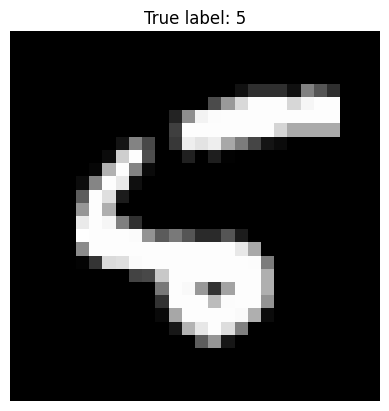

True: 5 - Predicted: 6 - Probability: 0.99999535


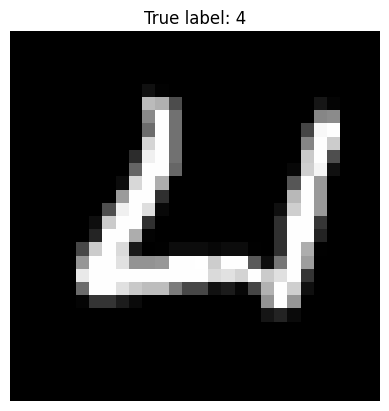

True: 4 - Predicted: 0 - Probability: 0.5348875


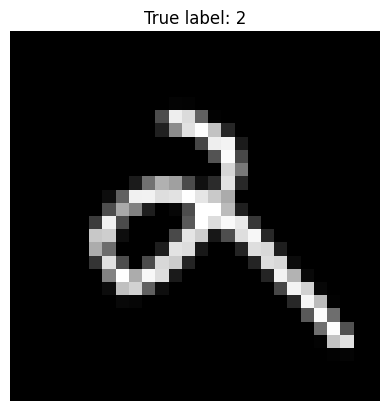

True: 2 - Predicted: 9 - Probability: 0.99815875


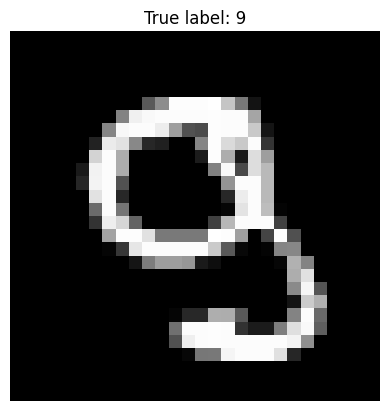

True: 9 - Predicted: 8 - Probability: 0.87400633


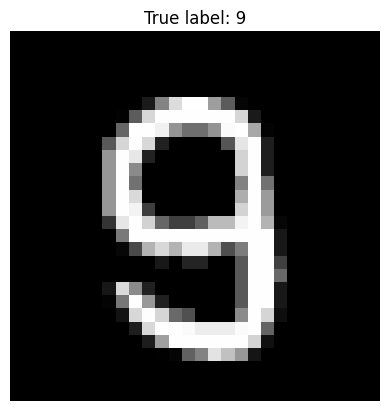

True: 9 - Predicted: 8 - Probability: 0.71410775


In [18]:
display_mistakes(5)